In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()
df = pd.read_csv("developer_activity.csv")

df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df["date"] = df["timestamp"].dt.date

print("Dataset loaded successfully!")
print("Rows:", len(df))
display(df.head())

Saving developer_activity.csv to developer_activity.csv
Dataset loaded successfully!
Rows: 32


,timestamp,developer_id,coding_minutes,interruption_count,context_switches,task_complexity,break_minutes,focus_score,cognitive_load_score,hour,date
0,2026-10-20 09:00:00,DEV001,42,1,2,3,5,78,35,9,2026-10-20
1,2026-10-20 10:00:00,DEV001,50,0,1,4,5,88,42,10,2026-10-20
2,2026-10-20 11:00:00,DEV001,35,3,5,4,5,61,68,11,2026-10-20
3,2026-10-20 12:00:00,DEV001,20,2,3,2,15,65,40,12,2026-10-20
4,2026-10-20 13:00:00,DEV001,45,1,2,5,10,76,63,13,2026-10-20


In [2]:
def classify_focus(score):
    if score >= 80:
        return "High Focus"
    elif score >= 60:
        return "Moderate Focus"
    else:
        return "Low Focus"

df["focus_category"] = df["focus_score"].apply(classify_focus)

display(
    df[["developer_id", "timestamp",
        "focus_score", "focus_category"]].head(10)
)

,developer_id,timestamp,focus_score,focus_category
0,DEV001,2026-10-20 09:00:00,78,Moderate Focus
1,DEV001,2026-10-20 10:00:00,88,High Focus
2,DEV001,2026-10-20 11:00:00,61,Moderate Focus
3,DEV001,2026-10-20 12:00:00,65,Moderate Focus
4,DEV001,2026-10-20 13:00:00,76,Moderate Focus
5,DEV001,2026-10-20 14:00:00,90,High Focus
6,DEV001,2026-10-20 15:00:00,54,Low Focus
7,DEV001,2026-10-20 16:00:00,69,Moderate Focus
8,DEV002,2026-10-20 09:00:00,70,Moderate Focus
9,DEV002,2026-10-20 10:00:00,82,High Focus


In [3]:
focus_summary = df.groupby("developer_id").agg(
    average_focus=("focus_score", "mean"),
    average_coding_minutes=("coding_minutes", "mean"),
    total_interruptions=("interruption_count", "sum"),
    average_context_switches=("context_switches", "mean"),
    average_cognitive_load=("cognitive_load_score", "mean")
).round(2)

display(focus_summary)

,average_focus,average_coding_minutes,total_interruptions,average_context_switches,average_cognitive_load
developer_id,,,,,
DEV001,72.94,38.12,26,2.88,51.00
DEV002,69.50,36.19,33,3.56,53.25


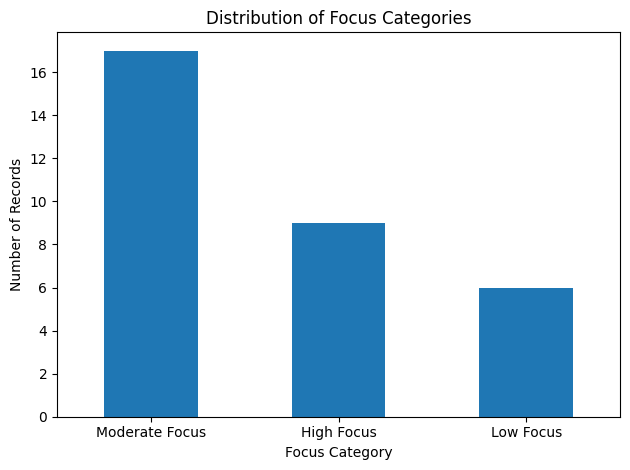

In [4]:
category_counts = df["focus_category"].value_counts()

category_counts.plot(kind="bar")
plt.title("Distribution of Focus Categories")
plt.xlabel("Focus Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

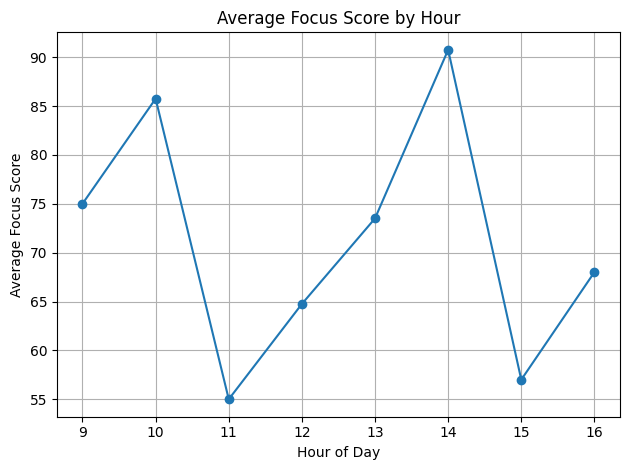

,focus_score
hour,
9,75.00
10,85.75
11,55.00
12,64.75
13,73.50
14,90.75
15,57.00
16,68.00


In [5]:
hourly_focus = df.groupby("hour")["focus_score"].mean()

hourly_focus.plot(
    kind="line",
    marker="o"
)

plt.title("Average Focus Score by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Focus Score")
plt.xticks(sorted(df["hour"].unique()))
plt.grid(True)
plt.tight_layout()
plt.show()

display(hourly_focus.round(2))

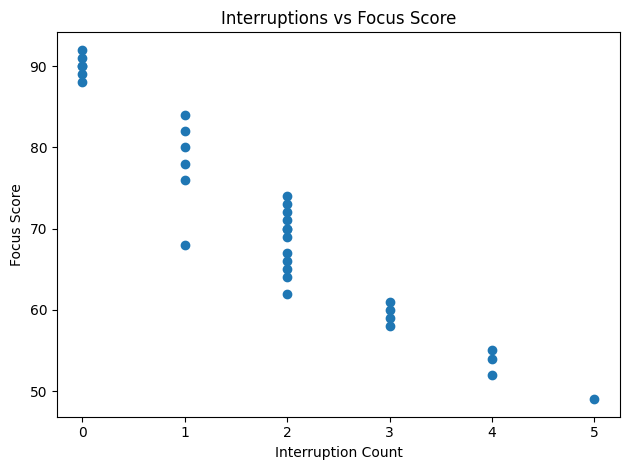

Correlation: -0.953


In [6]:
plt.scatter(
    df["interruption_count"],
    df["focus_score"]
)

plt.title("Interruptions vs Focus Score")
plt.xlabel("Interruption Count")
plt.ylabel("Focus Score")
plt.tight_layout()
plt.show()

correlation = df[
    ["interruption_count", "focus_score"]
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 3))

In [7]:
focus_summary.to_csv("focus_analysis_summary.csv")

df.to_csv("developer_activity_with_focus_categories.csv",
          index=False)

print("Analysis completed.")
print("Files created:")
print("- focus_analysis_summary.csv")
print("- developer_activity_with_focus_categories.csv")

Analysis completed.
Files created:
- focus_analysis_summary.csv
- developer_activity_with_focus_categories.csv
